In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Timing experiments
import time

# Feature scaling and preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

# Pipeline construction
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline

# Class imbalance
from imblearn.over_sampling import SMOTE, RandomOverSampler

In [2]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

# Random Forest
from sklearn.ensemble import RandomForestClassifier

# Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

# XGBoost
from xgboost import XGBClassifier

# LightGBM
from lightgbm import LGBMClassifier

# CatBoost
from catboost import CatBoostClassifier

# Cross-validation
from sklearn.model_selection import StratifiedKFold, cross_validate

# Classification metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc
)

# Hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV

# Model explainability
import shap

/home/emmizzy119/fraud-detection-system/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from pathlib import Path

# Directory containing the prepared data partitions
Split_Dir = Path("../data/processed")

# File paths
X_train_path = Split_Dir / "X_train.csv"
X_test_path = Split_Dir / "X_test.csv"
y_train_path = Split_Dir / "y_train.csv"
y_test_path = Split_Dir / "y_test.csv"

# Check whether all files exist
files ={
    "X_train": X_train_path,
    "X_test": X_test_path,
    "y_train": y_train_path,
    "y_test": y_test_path
}

for name, path in files.items():
    print(f"{name}: {'found' if path.exists() else 'not found'} - {path}")

X_train: found - ../data/processed/X_train.csv
X_test: found - ../data/processed/X_test.csv
y_train: found - ../data/processed/y_train.csv
y_test: found - ../data/processed/y_test.csv


In [4]:
X_train = pd.read_csv(X_train_path)
X_test = pd.read_csv(X_test_path)

y_train = pd.read_csv(y_train_path).squeeze("columns")
y_test = pd.read_csv(y_test_path).squeeze("columns")

print("Data loaded successfully.")

Data loaded successfully.


In [5]:
print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

print("\nTest features:", X_test.shape)
print("Test target:", y_test.shape)

Training features: (226980, 30)
Training target: (226980,)

Test features: (56746, 30)
Test target: (56746,)


In [6]:
print("Training target classes:")
print(y_train.value_counts().sort_index())

print("\nTest target classes:")
print(y_test.value_counts().sort_index())

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTest target proportions:")
print(y_test.value_counts(normalize=True).sort_index())

Training target classes:
Class
0    226602
1       378
Name: count, dtype: int64

Test target classes:
Class
0    56651
1       95
Name: count, dtype: int64

Training target proportions:
Class
0    0.998335
1    0.001665
Name: proportion, dtype: float64

Test target proportions:
Class
0    0.998326
1    0.001674
Name: proportion, dtype: float64


In [7]:
print("Same feature columns:", X_train.columns.equals(X_test.columns))
print("Training feature count:", X_train.shape[1])
print("Test feature count:", X_test.shape[1])

print("\nTraining columns:")
print(X_train.columns.tolist())

Same feature columns: True
Training feature count: 30
Test feature count: 30

Training columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


In [8]:
# Reproducibile experiment configuration
RANDOM_STATE = 42
N_SPLITS = 5

# Five-fold stratifired cross-validation
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

print(f"Number of folds: {N_SPLITS}")
print(f"Random state: {RANDOM_STATE}")

Number of folds: 5
Random state: 42


In [9]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "average_precision": "average_precision",
    "roc_auc": "roc_auc"
}

print("Evaluation metrics:")
for metric in scoring:
    print(f"- {metric}")

Evaluation metrics:
- accuracy
- precision
- recall
- f1
- average_precision
- roc_auc


In [10]:
# Models to compare
MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Gradient Boosting",
    "XGBoost",
    "LightGBM",
    "CatBoost"
]

# Imbalance-handling strategies
STRATEGY_NAMES = [
    "Class Weighting",
    "SMOTE Oversampling",
    "Random Undersampling"
]

TOTAL_EXPERIMENTS = len(MODEL_NAMES) * len(STRATEGY_NAMES)

print(f"Number of models: {len(MODEL_NAMES)}")
print(f"Number of imbalance strategies: {len(STRATEGY_NAMES)}")
print(f"Total model-strategy combinations: {TOTAL_EXPERIMENTS}")
print(f"Total cross-validation fits: {TOTAL_EXPERIMENTS * N_SPLITS}")

Number of models: 6
Number of imbalance strategies: 3
Total model-strategy combinations: 18
Total cross-validation fits: 90


In [11]:
# 1. Logistic Regression
logistic_regression = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

# 2. Random Forest
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=2
)

# 3. Gradient Boosting
gradient_boosting = GradientBoostingClassifier(
    random_state=RANDOM_STATE
)

# 4. XGBoost
xgboost_model = XGBClassifier(
    random_state=RANDOM_STATE,
    eval_metric="logloss",
    n_jobs=-1
)

# 5. LightGBM
lightgbm_model = LGBMClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

# 6. CatBoost
catboost_model = CatBoostClassifier(
    random_seed=RANDOM_STATE,
    verbose=0,
    thread_count=-1
)

# Collect the models
models = {
    "Logistic Regression": logistic_regression,
    "Random Forest": random_forest,
    "Gradient Boosting": gradient_boosting,
    "XGBoost": xgboost_model,
    "LightGBM": lightgbm_model,
    "CatBoost": catboost_model
}

print(f"Models defined: {len(models)}")

for name in models:
    print(name)

Models defined: 6
Logistic Regression
Random Forest
Gradient Boosting
XGBoost
LightGBM
CatBoost


In [12]:
from imblearn.under_sampling import RandomUnderSampler

In [13]:
# Columns to scale for Logistic Regression
scale_columns = ["Time", "Amount"]

# All predictors are numerical
all_feature_columns = X_train.columns.tolist()

print("Number of features:", len(all_feature_columns))
print("Columns scaled for Logistic Regression:", scale_columns)
print("Features scaled before SMOTE:", len(all_feature_columns))

Number of features: 30
Columns scaled for Logistic Regression: ['Time', 'Amount']
Features scaled before SMOTE: 30


In [14]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler


def build_pipeline(model, strategy):
    """Build a model pipeline for the selected imbalance strategy."""

    model = clone(model)
    steps = []

    supported_models = (
        LogisticRegression,
        RandomForestClassifier,
        GradientBoostingClassifier,
        XGBClassifier,
        LGBMClassifier,
        CatBoostClassifier
    )

    if not isinstance(model, supported_models):
        raise TypeError(f"Unsupported model type: {type(model).__name__}")

    if strategy == "Class Weighting":

        if isinstance(model, LogisticRegression):
            steps.append((
                "scaler",
                ColumnTransformer(
                    transformers=[
                        ("scale", StandardScaler(), ["Time", "Amount"])
                    ],
                    remainder="passthrough"
                )
            ))

        if isinstance(model, (LogisticRegression, RandomForestClassifier)):
            model.set_params(class_weight="balanced")

        elif isinstance(model, XGBClassifier):
            model = ClassWeightedClassifier(model)

        elif isinstance(model, GradientBoostingClassifier):
            model = ClassWeightedClassifier(model)

        elif isinstance(model, LGBMClassifier):
            model.set_params(class_weight="balanced")

        elif isinstance(model, CatBoostClassifier):
            model.set_params(auto_class_weights="Balanced")

    elif strategy == "SMOTE Oversampling":
        steps.append(("scaler", StandardScaler()))
        steps.append(("sampler", SMOTE(random_state=RANDOM_STATE)))

    elif strategy == "Random Undersampling":

        if isinstance(model, LogisticRegression):
            steps.append((
                "scaler",
                ColumnTransformer(
                    transformers=[
                        ("scale", StandardScaler(), ["Time", "Amount"])
                    ],
                    remainder="passthrough"
                )
            ))

        steps.append((
            "sampler",
            RandomUnderSampler(random_state=RANDOM_STATE)
        ))

    else:
        raise ValueError(f"Unknown strategy: {strategy}")

    steps.append(("classifier", model))

    return ImbPipeline(steps=steps)

In [15]:
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.utils.validation import check_is_fitted


class ClassWeightedClassifier(ClassifierMixin, BaseEstimator):

    def __init__(self, estimator):
        self.estimator = estimator

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator)

        # Calculate weights using this fold's training labels.
        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y
        )

        # XGBoost uses scale_pos_weight instead.
        if isinstance(self.estimator_, XGBClassifier):
            class_counts = np.bincount(np.asarray(y, dtype=int))
            self.estimator_.set_params(
                scale_pos_weight=class_counts[0] / class_counts[1]
            )
            self.estimator_.fit(X, y)

        # Gradient Boosting accepts sample_weight directly.
        elif isinstance(self.estimator_, GradientBoostingClassifier):
            self.estimator_.fit(
                X, y,
                sample_weight=sample_weights
            )

        else:
            raise TypeError(
                "This wrapper supports Gradient Boosting and XGBoost."
            )

        self.classes_ = self.estimator_.classes_
        return self

    def predict(self, X):
        check_is_fitted(self, "estimator_")
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        check_is_fitted(self, "estimator_")
        return self.estimator_.predict_proba(X) 

In [16]:
def evaluate_model(model, strategy, X_train, y_train, cv, scoring):
    """
    Evaluate one model-strategy combination using cross-validation.
    """

    pipeline = build_pipeline(model, strategy)

    start_time = time.time()

    cv_results = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=2,
        return_train_score=False,
        error_score="raise"
    )

    elapsed_time = time.time() - start_time

    results = {
        "model": type(model).__name__,
        "strategy": strategy,
        "total_time_seconds": elapsed_time
    }

    for metric in scoring:
        scores = cv_results[f"test_{metric}"]

        results[f"{metric}_mean"] = scores.mean()
        results[f"{metric}_std"] = scores.std()

    return results

In [17]:
experiments = {
    f"{model_name} - {strategy}": {
        "model": model,
        "strategy": strategy
    }
    for model_name, model in models.items()
    for strategy in STRATEGY_NAMES
}

In [18]:
print(f"Total experiments: {len(experiments)}")

for experiment_name in experiments:
    print(experiment_name)

Total experiments: 18
Logistic Regression - Class Weighting
Logistic Regression - SMOTE Oversampling
Logistic Regression - Random Undersampling
Random Forest - Class Weighting
Random Forest - SMOTE Oversampling
Random Forest - Random Undersampling
Gradient Boosting - Class Weighting
Gradient Boosting - SMOTE Oversampling
Gradient Boosting - Random Undersampling
XGBoost - Class Weighting
XGBoost - SMOTE Oversampling
XGBoost - Random Undersampling
LightGBM - Class Weighting
LightGBM - SMOTE Oversampling
LightGBM - Random Undersampling
CatBoost - Class Weighting
CatBoost - SMOTE Oversampling
CatBoost - Random Undersampling


In [19]:
experiment_results = []

for experiment_name, experiment_config in experiments.items():

    print(f"\nRunning: {experiment_name}")

    results = evaluate_model(
        model=experiment_config["model"],
        strategy=experiment_config["strategy"],
        X_train=X_train,
        y_train=y_train,
        cv=cv,
        scoring=scoring
    )

    experiment_results.append(results)

    print(
        f"Average Precision: "
        f"{results['average_precision_mean']:.4f}"
    )

    print(
        f"Recall: "
        f"{results['recall_mean']:.4f}"
    )

    print(
        f"Elapsed time: "
        f"{results['total_time_seconds']:.2f} seconds"
    )


Running: Logistic Regression - Class Weighting


KeyboardInterrupt: 

In [26]:
results_df = pd.read_csv("../data/processed/experiment_results.csv")

In [27]:
results_df = results_df.sort_values(by="average_precision_mean", ascending=False).reset_index(drop=True)
results_df

,model,strategy,total_time_seconds,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std
0,XGBClassifier,Class Weighting,15.788576,0.999590,0.000062,0.926904,0.025173,0.820035,0.046357,0.869012,0.022791,0.848342,0.029766,0.978911,0.005033
1,XGBClassifier,SMOTE Oversampling,31.825407,0.999299,0.000101,0.775456,0.048408,0.822702,0.050679,0.796400,0.028219,0.843567,0.033383,0.977584,0.005534
2,RandomForestClassifier,SMOTE Oversampling,742.748949,0.999537,0.000084,0.892634,0.034240,0.822737,0.043013,0.855322,0.027404,0.842494,0.028746,0.973781,0.014893
3,CatBoostClassifier,Class Weighting,178.696434,0.999423,0.000092,0.819795,0.037613,0.841263,0.044847,0.829183,0.026861,0.838022,0.039847,0.975693,0.005212
4,CatBoostClassifier,SMOTE Oversampling,368.832210,0.999013,0.000124,0.663605,0.043614,0.841263,0.040016,0.740168,0.023637,0.837327,0.036461,0.973078,0.004705
5,RandomForestClassifier,Class Weighting,151.416891,0.999533,0.000069,0.921052,0.020973,0.788246,0.051903,0.848139,0.026879,0.834693,0.027444,0.959212,0.015570
6,LGBMClassifier,Class Weighting,365.338031,0.999493,0.000101,0.867024,0.031061,0.822667,0.050693,0.843440,0.033225,0.828779,0.021267,0.966521,0.010305
7,LGBMClassifier,SMOTE Oversampling,396.603444,0.998885,0.000166,0.626994,0.051759,0.838596,0.032844,0.715963,0.032560,0.792850,0.037155,0.972371,0.004095
8,GradientBoostingClassifier,SMOTE Oversampling,2677.671663,0.990453,0.001345,0.137910,0.016212,0.883579,0.031641,0.238139,0.024396,0.765207,0.030582,0.977930,0.010439
9,RandomForestClassifier,Random Undersampling,2.977862,0.979571,0.002752,0.069568,0.008845,0.894140,0.032367,0.128953,0.015229,0.757918,0.053193,0.979060,0.010624


In [28]:
results_df[
    [
        "model",
        "strategy",
        "accuracy_mean",
        "precision_mean",
        "recall_mean",
        "f1_mean",
        "average_precision_mean",
        "roc_auc_mean",
        "total_time_seconds"
    ]
]

,model,strategy,accuracy_mean,precision_mean,recall_mean,f1_mean,average_precision_mean,roc_auc_mean,total_time_seconds
0,XGBClassifier,Class Weighting,0.999590,0.926904,0.820035,0.869012,0.848342,0.978911,15.788576
1,XGBClassifier,SMOTE Oversampling,0.999299,0.775456,0.822702,0.796400,0.843567,0.977584,31.825407
2,RandomForestClassifier,SMOTE Oversampling,0.999537,0.892634,0.822737,0.855322,0.842494,0.973781,742.748949
3,CatBoostClassifier,Class Weighting,0.999423,0.819795,0.841263,0.829183,0.838022,0.975693,178.696434
4,CatBoostClassifier,SMOTE Oversampling,0.999013,0.663605,0.841263,0.740168,0.837327,0.973078,368.832210
5,RandomForestClassifier,Class Weighting,0.999533,0.921052,0.788246,0.848139,0.834693,0.959212,151.416891
6,LGBMClassifier,Class Weighting,0.999493,0.867024,0.822667,0.843440,0.828779,0.966521,365.338031
7,LGBMClassifier,SMOTE Oversampling,0.998885,0.626994,0.838596,0.715963,0.792850,0.972371,396.603444
8,GradientBoostingClassifier,SMOTE Oversampling,0.990453,0.137910,0.883579,0.238139,0.765207,0.977930,2677.671663
9,RandomForestClassifier,Random Undersampling,0.979571,0.069568,0.894140,0.128953,0.757918,0.979060,2.977862


In [29]:
from pathlib import Path

results_dir = Path("../data/processed")
results_dir.mkdir(parents=True, exist_ok=True)

results_path = results_dir / "experiment_results.csv"

results_df.to_csv(results_path, index=False)

print(f"Results saved to: {results_path.resolve()}")

Results saved to: /home/emmizzy119/fraud-detection-system/data/processed/experiment_results.csv


In [30]:
xgb_class_weight_pipeline = build_pipeline(
    model=models["XGBoost"],
    strategy="Class Weighting"
)

In [31]:
xgb_cv_results = cross_validate(
    estimator=xgb_class_weight_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False,
    return_estimator=True,
    error_score="raise"
)

In [32]:
xgb_cv_summary = {
    "model": "XGBoost",
    "strategy": "Class Weighting"
}

for metric in scoring:
    scores = xgb_cv_results[f"test_{metric}"]

    xgb_cv_summary[f"{metric}_mean"] = scores.mean()
    xgb_cv_summary[f"{metric}_std"] = scores.std()

pd.DataFrame([xgb_cv_summary])

,model,strategy,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std
0,XGBoost,Class Weighting,0.99959,0.000062,0.926904,0.025173,0.820035,0.046357,0.869012,0.022791,0.848342,0.029766,0.978911,0.005033


In [33]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold

# Generate the same fold assignments used by cross-validation
folds = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Store each observation's prediction from its held-out fold
oof_predictions = np.zeros(len(y_train), dtype=int)
oof_probabilities = np.zeros(len(y_train), dtype=float)

for fold_idx, (train_idx, val_idx) in enumerate(
    folds.split(X_train, y_train)
):
    # Retrieve the fitted estimator for this fold
    fitted_pipeline = xgb_cv_results["estimator"][fold_idx]

    # Predict only the observations held out from this fold
    X_fold_val = X_train.iloc[val_idx]

    oof_predictions[val_idx] = fitted_pipeline.predict(X_fold_val)

    oof_probabilities[val_idx] = (
        fitted_pipeline.predict_proba(X_fold_val)[:, 1]
    )

print("Out-of-fold predictions generated.")
print("Number of predictions:", len(oof_predictions))

Out-of-fold predictions generated.
Number of predictions: 226980


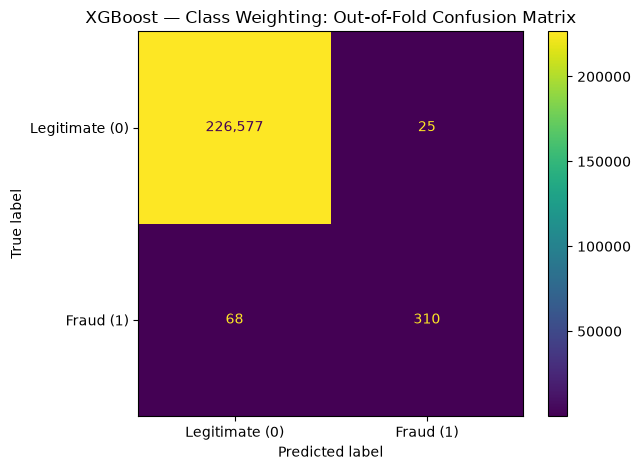

Confusion matrix:
[[226577     25]
 [    68    310]]


In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_train,
    oof_predictions,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate (0)", "Fraud (1)"]
)

display.plot(values_format=",d")
plt.title("XGBoost — Class Weighting: Out-of-Fold Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)

In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

xgb_metrics = {
    "Accuracy": accuracy_score(y_train, oof_predictions),
    "Precision": precision_score(y_train, oof_predictions),
    "Recall": recall_score(y_train, oof_predictions),
    "F1 Score": f1_score(y_train, oof_predictions),
    "Average Precision": average_precision_score(
        y_train, oof_probabilities
    ),
    "ROC-AUC": roc_auc_score(y_train, oof_probabilities)
}

pd.DataFrame(
    xgb_metrics.items(),
    columns=["Metric", "Value"]
)

,Metric,Value
0,Accuracy,0.999590
1,Precision,0.925373
2,Recall,0.820106
3,F1 Score,0.869565
4,Average Precision,0.847170
5,ROC-AUC,0.978893


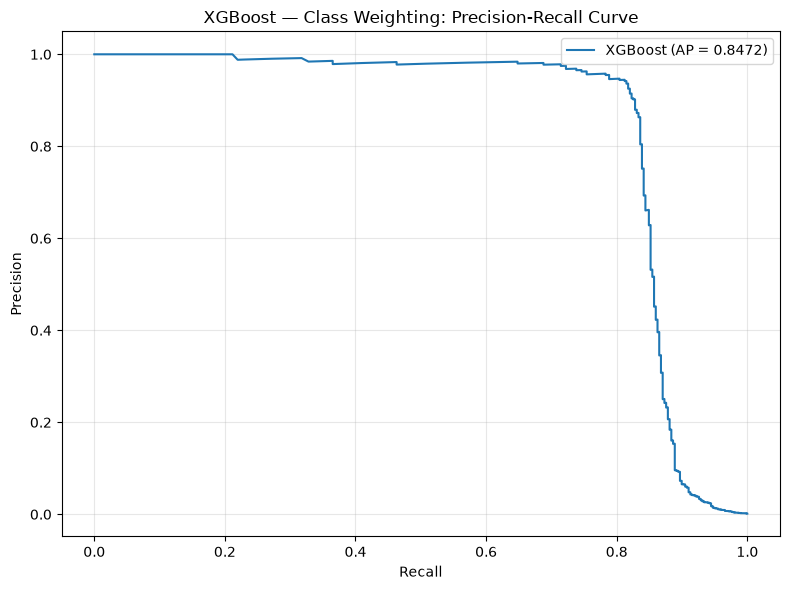

In [36]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Calculate precision and recall across classification thresholds
precision_values, recall_values, thresholds = precision_recall_curve(
    y_train,
    oof_probabilities
)

average_precision = average_precision_score(
    y_train,
    oof_probabilities
)

# Plot the precision-recall curve
plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"XGBoost (AP = {average_precision:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("XGBoost — Class Weighting: Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds_to_test = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

threshold_results = []

for threshold in thresholds_to_test:
    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "fraud_alerts": int(predictions.sum())
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)

,threshold,precision,recall,f1,fraud_alerts
0,0.1,0.8251,0.8360,0.8305,383
1,0.2,0.8678,0.8333,0.8502,363
2,0.3,0.8994,0.8280,0.8623,348
3,0.4,0.9067,0.8228,0.8627,343
4,0.5,0.9254,0.8201,0.8696,335
5,0.6,0.9307,0.8175,0.8704,332
6,0.7,0.9364,0.8175,0.8729,330
7,0.8,0.9364,0.8175,0.8729,330
8,0.9,0.9444,0.8095,0.8718,324


# XGBoost with Class Weighting: Model Investigation and Evaluation

## 1. Objective

This investigation evaluates XGBoost with class weighting as a candidate model for the credit card fraud detection system.

The dataset is highly imbalanced, with legitimate transactions substantially outnumbering fraudulent transactions. Consequently, accuracy alone is insufficient for evaluating model performance. A model could achieve very high accuracy by predicting most transactions as legitimate while failing to detect a meaningful proportion of fraud.

The investigation therefore focuses on precision, recall, F1 score, Average Precision, ROC-AUC, the confusion matrix, and the effect of changing the classification threshold.

The objective is to understand the model's ability to detect fraudulent transactions while controlling false alarms.

## 2. Experimental Configuration

| Component | Configuration |
|---|---|
| Model | XGBoost Classifier |
| Imbalance-handling strategy | Class Weighting |
| Validation method | 5-fold Stratified Cross-Validation |
| Cross-validation predictions | Out-of-fold predictions |
| Positive class | Fraud (`Class = 1`) |
| Negative class | Legitimate (`Class = 0`) |
| Default classification threshold | 0.5 |
| Final test set | Reserved for final model evaluation |

Class weighting assigns greater importance to fraudulent transactions during model training. This helps the classifier learn from the minority class without requiring the original training data to be resampled.

### Evaluation methodology

The initial cross-validation experiment produced a set of metrics for each fold. The fitted estimators were retained using `return_estimator=True`.

Each fitted estimator then predicted the observations belonging to its held-out fold. Combining these predictions produced out-of-fold predictions for the entire training dataset.

This approach provides predictions for observations that were not used to fit the corresponding model, making the combined predictions suitable for investigating classification performance.

The final test set was not used during this investigation.

## 3. Cross-Validation Results

The original five-fold cross-validation experiment produced the following mean metrics and standard deviations.

| Metric | Mean | Standard Deviation |
|---|---:|---:|
| Accuracy | 0.999590 | 0.000062 |
| Precision | 0.926904 | 0.025173 |
| Recall | 0.820035 | 0.046357 |
| F1 score | 0.869012 | 0.022791 |
| Average Precision | 0.848342 | 0.029766 |
| ROC-AUC | 0.978911 | 0.005033 |

### Interpretation

**Accuracy:** The mean accuracy was approximately 99.96%. However, accuracy is not sufficient for judging this model because legitimate transactions dominate the dataset.

**Precision:** Mean precision was approximately 92.69%. This indicates that, on average across the folds, a high proportion of transactions predicted as fraudulent were actually fraudulent.

**Recall:** Mean recall was approximately 82.00%. The model detected approximately 82% of fraudulent transactions across the validation folds, while missing the remainder.

**F1 score:** The mean F1 score was approximately 86.90%, indicating a reasonably strong balance between precision and recall.

**Average Precision:** The mean Average Precision was approximately 84.83%. This summarizes the precision-recall trade-off across classification thresholds and is particularly useful for evaluating models on highly imbalanced datasets.

**ROC-AUC:** The mean ROC-AUC was approximately 97.89%, indicating strong discrimination between fraudulent and legitimate transactions across classification thresholds.

### Cross-validation stability

The standard deviations provide information about variation across folds. ROC-AUC had a relatively small standard deviation of approximately 0.0050, while recall had a larger standard deviation of approximately 0.0464.

This suggests that the model's ranking performance was more consistent across folds than its ability to detect fraud at the default classification threshold.

These standard deviations measure variation between folds; they are not confidence intervals.

## 4. Out-of-Fold Confusion Matrix

The confusion matrix was calculated using the combined out-of-fold predictions.

| Actual Class | Predicted Legitimate (0) | Predicted Fraud (1) |
|---|---:|---:|
| Legitimate (0) | 226,577 | 25 |
| Fraud (1) | 68 | 310 |

The matrix contains four important quantities:

- **True Negatives (TN): 226,577** — legitimate transactions correctly classified as legitimate.
- **False Positives (FP): 25** — legitimate transactions incorrectly classified as fraudulent.
- **False Negatives (FN): 68** — fraudulent transactions incorrectly classified as legitimate.
- **True Positives (TP): 310** — fraudulent transactions correctly classified as fraudulent.

### Confusion matrix interpretation

The model correctly identified 310 fraudulent transactions out of 378 fraudulent transactions in the out-of-fold predictions.

However, it missed 68 fraudulent transactions. These false negatives are important because missed fraud may result in financial losses.

The model also generated 25 false-positive alerts. Although these legitimate transactions were incorrectly flagged, the number of false positives was relatively small compared with the number of legitimate transactions evaluated.

This suggests that the model achieves a useful balance between detecting fraud and limiting false alarms at the default classification threshold.

### Metrics calculated from the out-of-fold predictions

| Metric | Value |
|---|---:|
| Accuracy | 99.9590% |
| Precision | 92.5373% |
| Recall | 82.0106% |
| F1 score | 86.9565% |
| Average Precision | 84.7170% |
| ROC-AUC | 97.8893% |

The out-of-fold metrics differ slightly from the original cross-validation means because the former are calculated from the combined predictions, while the latter average the scores calculated independently for each fold.

### Operational implications

At the default threshold of 0.5, the model detected approximately 82% of fraud cases and maintained precision above 92%.

Nevertheless, the 68 missed fraudulent transactions indicate that there may be opportunities to improve recall. Whether additional fraud detection justifies more false alarms depends on the operational cost of investigating legitimate transactions and the financial impact of missed fraud.

## 5. Precision-Recall Curve

The precision-recall curve evaluates how precision and recall change as the classification threshold varies.

The curve produced an Average Precision score of approximately **0.8472**.

### Observations

**High precision at lower recall levels**

At lower recall levels, precision remained close to 1.0. This indicates that the model can make highly precise fraud predictions when operating at thresholds that identify a smaller subset of the fraudulent transactions.

However, this comes at the cost of missing more fraudulent transactions.

**A relatively strong trade-off at moderate-to-high recall**

As recall increases, precision gradually decreases. The curve maintains relatively high precision across a substantial range of recall values before declining more sharply.

This indicates that the model can detect additional fraud while maintaining useful precision over part of its operating range.

**A sharp decline at high recall**

When recall approaches the upper end of the curve, precision decreases substantially. This suggests that attempting to capture nearly all fraudulent transactions would result in many more legitimate transactions being flagged.

### Interpretation

The precision-recall curve demonstrates why the classification threshold matters.

The default threshold of 0.5 is not necessarily the best operating threshold for a fraud detection system. A higher threshold may reduce false alarms, while a lower threshold may detect more fraud.

The appropriate threshold must be selected according to the desired trade-off between missed fraud and false-positive alerts.

Average Precision summarizes performance across the curve; it does not indicate the precision or recall at any particular threshold.

## 6. ROC Curve and ROC-AUC

The ROC curve examines the relationship between the true-positive rate and the false-positive rate across classification thresholds.

The original cross-validation experiment produced a mean ROC-AUC of approximately **0.9789**, while the combined out-of-fold predictions produced an ROC-AUC of approximately **0.9789**.

### Interpretation

A high ROC-AUC indicates that the model generally assigns higher fraud scores to fraudulent transactions than to legitimate transactions.

However, ROC-AUC must be interpreted alongside the precision-recall results. In a highly imbalanced dataset, the false-positive rate can appear small even when the number of false-positive predictions is operationally meaningful.

The ROC-AUC result is therefore encouraging, but it does not replace the need to examine precision, recall, and the confusion matrix.

## 7. Classification Threshold Analysis

The default classification threshold is 0.5. To investigate alternative operating points, precision, recall, F1 score, and the number of predicted fraud alerts were calculated at nine thresholds.

| Threshold | Precision | Recall | F1 Score | Fraud Alerts |
|---:|---:|---:|---:|---:|
| 0.1 | 0.8251 | 0.8360 | 0.8305 | 383 |
| 0.2 | 0.8678 | 0.8333 | 0.8502 | 363 |
| 0.3 | 0.8994 | 0.8280 | 0.8623 | 348 |
| 0.4 | 0.9067 | 0.8228 | 0.8627 | 343 |
| 0.5 | 0.9254 | 0.8201 | 0.8696 | 335 |
| 0.6 | 0.9307 | 0.8175 | 0.8704 | 332 |
| 0.7 | 0.9364 | 0.8175 | 0.8729 | 330 |
| 0.8 | 0.9364 | 0.8175 | 0.8729 | 330 |
| 0.9 | 0.9444 | 0.8095 | 0.8718 | 324 |

### Observations

**Lower thresholds increase recall**

At a threshold of 0.1, recall increased to 83.60%, compared with 82.01% at the default threshold of 0.5. However, the model generated 383 fraud alerts instead of 335, and precision decreased to 82.51%.

This illustrates the cost of trying to detect additional fraud: more legitimate transactions may be incorrectly flagged.

**Higher thresholds improve precision**

At a threshold of 0.7, precision increased to 93.64%, while recall remained approximately 81.75%. The number of fraud alerts decreased to 330.

At a threshold of 0.9, precision increased further to 94.44%, but recall decreased to 80.95%.

**The highest observed F1 score occurred at thresholds 0.7 and 0.8**

Both thresholds produced an F1 score of 0.8729 in the tested results. However, maximizing F1 alone does not necessarily produce the best operating threshold for a fraud detection application.

The identical results at thresholds 0.7 and 0.8 indicate that these thresholds produced the same predicted classes for the evaluated observations.

### Threshold decision

The results suggest that 0.7 is a useful candidate for further investigation because it produced higher precision than the default threshold without reducing recall relative to the 0.6 threshold.

However, **0.7 is not yet the final selected threshold**. The final decision must consider the business cost of missed fraud and false-positive alerts, as well as the stability of the results.

The test set must remain untouched during threshold selection.

## 8. Strengths and Limitations

### Strengths

- High precision at the default classification threshold.
- Recall of approximately 82%, indicating that the model detects most fraudulent transactions.
- Strong F1 score, reflecting a useful balance between precision and recall.
- High Average Precision, supporting its suitability for further investigation on an imbalanced dataset.
- High ROC-AUC, indicating strong ranking ability.
- Relatively few false-positive alerts in the out-of-fold confusion matrix.
- The threshold analysis provides a practical way to explore alternative operating points.

### Limitations

- The model still misses 68 fraudulent transactions in the combined out-of-fold predictions.
- Lowering the classification threshold increases false-positive alerts.
- Higher precision at a higher threshold can come at the expense of recall.
- Cross-validation results do not guarantee the same performance on unseen data.
- The optimal threshold cannot be determined from the metrics alone without considering operational costs.
- The investigation has not yet established final test-set performance.

## 9. Overall Conclusion

XGBoost with Class Weighting is a strong candidate for the credit card fraud detection system.

The five-fold cross-validation results show high precision, strong ROC-AUC, and a useful balance between precision and recall. The out-of-fold confusion matrix confirms that the model detected 310 of 378 fraudulent transactions while generating 25 false-positive alerts.

The precision-recall curve indicates that the model maintains high precision over a substantial range of recall values, although precision decreases sharply when recall is pushed toward the upper end of the curve.

The threshold analysis suggests that higher thresholds may improve precision and reduce the number of fraud alerts. A threshold of 0.7 is a candidate for further evaluation, but it should not be treated as the final threshold without additional analysis.

**Decision:** Retain XGBoost with Class Weighting as one of the three candidate models. Compare it with Random Forest using SMOTE Oversampling and CatBoost using Class Weighting before choosing a final model.

The next investigation will evaluate Random Forest with SMOTE Oversampling using the same general methodology. After all three candidates have been investigated, their results will be compared before fine-tuning and final model selection.

In [38]:
rf_smote_pipeline = build_pipeline(
    model=models["Random Forest"],
    strategy="SMOTE Oversampling"
)

rf_smote_pipeline

,steps,"[('scaler', ...), ('sampler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,random_state,42
,sampling_strategy,'auto'
,k_neighbors,5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",2


In [39]:
rf_smote_cv_results = cross_validate(
    estimator=rf_smote_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False,
    return_estimator=True,
    error_score="raise"
)

In [40]:
rf_smote_summary = {
    "model": "Random Forest",
    "strategy": "SMOTE Oversampling"
}

for metric in scoring:
    scores = rf_smote_cv_results[f"test_{metric}"]

    rf_smote_summary[f"{metric}_mean"] = scores.mean()
    rf_smote_summary[f"{metric}_std"] = scores.std()

rf_smote_summary_df = pd.DataFrame([rf_smote_summary])

rf_smote_summary_df

,model,strategy,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std
0,Random Forest,SMOTE Oversampling,0.999537,0.000084,0.892634,0.03424,0.822737,0.043013,0.855322,0.027404,0.842494,0.028746,0.973781,0.014893


In [41]:
rf_smote_oof_predictions = np.zeros(len(y_train), dtype=int)
rf_smote_oof_probabilities = np.zeros(len(y_train), dtype=float)

for fold_idx, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train)
):
    fitted_pipeline = rf_smote_cv_results["estimator"][fold_idx]

    X_fold_val = X_train.iloc[val_idx]

    rf_smote_oof_predictions[val_idx] = fitted_pipeline.predict(
        X_fold_val
    )

    rf_smote_oof_probabilities[val_idx] = (
        fitted_pipeline.predict_proba(X_fold_val)[:, 1]
    )

print("Out-of-fold predictions generated.")
print("Number of predictions:", len(rf_smote_oof_predictions))

Out-of-fold predictions generated.
Number of predictions: 226980


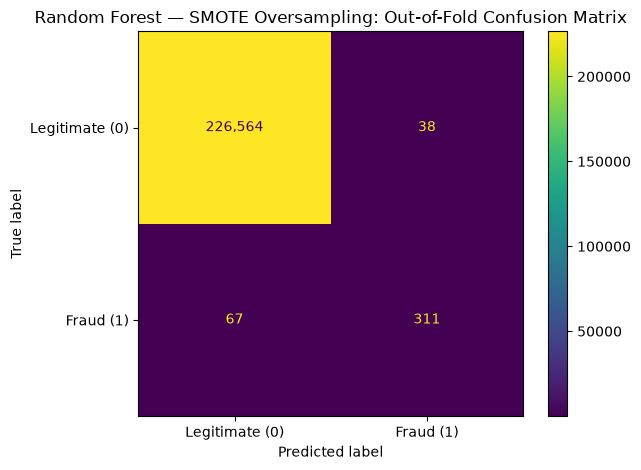

[[226564     38]
 [    67    311]]


In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

rf_smote_cm = confusion_matrix(
    y_train,
    rf_smote_oof_predictions,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=rf_smote_cm,
    display_labels=["Legitimate (0)", "Fraud (1)"]
)

display.plot(values_format=",d")
plt.title("Random Forest — SMOTE Oversampling: Out-of-Fold Confusion Matrix")
plt.tight_layout()
plt.show()

print(rf_smote_cm)

# Random Forest with SMOTE Oversampling: Model Investigation

## 1. Objective

This investigation evaluates Random Forest with SMOTE (Synthetic Minority Oversampling Technique) as an approach to credit card fraud detection.

The dataset is highly imbalanced, with legitimate transactions substantially outnumbering fraudulent transactions. This imbalance can make it difficult for a classifier to learn the characteristics of fraudulent transactions.

SMOTE addresses this issue by generating synthetic examples of the minority class during model training. The objective is to improve fraud detection while maintaining a reasonable balance between precision and recall.

The investigation examines cross-validation performance and out-of-fold predictions to understand how effectively the model distinguishes fraudulent transactions from legitimate ones.

## 2. Experimental Configuration

| Component | Configuration |
|---|---|
| Model | Random Forest Classifier |
| Imbalance-handling strategy | SMOTE Oversampling |
| Validation method | 5-fold Stratified Cross-Validation |
| Prediction method | Out-of-fold predictions |
| Positive class | Fraud (`Class = 1`) |
| Negative class | Legitimate (`Class = 0`) |
| Final test set | Reserved for final model evaluation |

### Pipeline configuration

The pipeline consists of the following steps:

1. **StandardScaler:** Standardizes the input features before SMOTE is applied.
2. **SMOTE:** Generates synthetic examples of fraudulent transactions within each training fold.
3. **Random Forest:** Learns to classify transactions using the resampled training data.

SMOTE is applied only to the training portion of each cross-validation fold. The validation portion retains its original class distribution, allowing evaluation under the natural imbalance of the dataset.

This is important because oversampling the entire dataset before cross-validation could introduce data leakage and produce misleading evaluation results.

## 3. Cross-Validation Results

The model was evaluated using five-fold stratified cross-validation.

| Metric | Mean | Standard Deviation |
|---|---:|---:|
| Accuracy | 0.999537 | 0.000084 |
| Precision | 0.892634 | 0.034240 |
| Recall | 0.822737 | 0.043013 |
| F1 score | 0.855322 | 0.027404 |
| Average Precision | 0.842494 | 0.028746 |
| ROC-AUC | 0.973781 | 0.014893 |

### Interpretation of the metrics

**Accuracy — 99.9537%**

The model correctly classified approximately 99.95% of transactions on average. However, because legitimate transactions dominate the dataset, accuracy alone does not adequately describe fraud detection performance.

**Precision — 89.26%**

The mean precision indicates that approximately 89.26% of transactions predicted as fraudulent were actually fraudulent, averaged across the five validation folds.

Higher precision generally means fewer legitimate transactions are incorrectly flagged as fraud.

**Recall — 82.27%**

The model achieved a mean recall of approximately 82.27%. This indicates that it detected about 82% of fraudulent transactions across the validation folds.

The remaining fraudulent transactions were missed by the classifier.

**F1 score — 85.53%**

The mean F1 score was approximately 85.53%. F1 combines precision and recall using their harmonic mean, providing a single measure of the balance between them.

**Average Precision — 84.25%**

The mean Average Precision was approximately 84.25%. This summarizes precision-recall performance across classification thresholds and is useful when evaluating models on highly imbalanced datasets.

**ROC-AUC — 97.38%**

The mean ROC-AUC was approximately 97.38%, indicating strong ability to distinguish fraudulent transactions from legitimate transactions across different classification thresholds.

### Cross-validation stability

The standard deviations show how much the metric values varied across the five folds.

Recall had a standard deviation of approximately 0.0430, while ROC-AUC had a standard deviation of approximately 0.0149.

These values indicate some variation in performance between folds. The results should therefore be interpreted as estimates of generalization performance rather than guarantees of performance on unseen data.

The standard deviations represent variation across folds, not confidence intervals.

## 4. Out-of-Fold Confusion Matrix

The confusion matrix was generated from out-of-fold predictions for the training dataset.

| Actual Class | Predicted Legitimate (0) | Predicted Fraud (1) |
|---|---:|---:|
| Legitimate (0) | 226,564 | 38 |
| Fraud (1) | 67 | 311 |

The confusion matrix contains four outcomes:

- **True Negatives (TN): 226,564** — legitimate transactions correctly classified as legitimate.
- **False Positives (FP): 38** — legitimate transactions incorrectly classified as fraudulent.
- **False Negatives (FN): 67** — fraudulent transactions incorrectly classified as legitimate.
- **True Positives (TP): 311** — fraudulent transactions correctly classified as fraudulent.

### Confusion matrix interpretation

The model correctly identified 311 fraudulent transactions and missed 67 fraudulent transactions in the out-of-fold predictions.

It also incorrectly flagged 38 legitimate transactions as fraudulent.

These results show that the model detected a substantial proportion of fraudulent transactions while producing a relatively small number of false-positive alerts compared with the total number of legitimate transactions evaluated.

However, the 67 missed fraud cases remain important. In a real fraud detection system, missed fraud may lead to financial losses, while false-positive alerts may require additional investigation and inconvenience legitimate customers.

### Metrics calculated from the out-of-fold predictions

| Metric | Value |
|---|---:|
| Accuracy | 99.9537% |
| Precision | 89.1087% |
| Recall | 82.2751% |
| F1 score | 85.5358% |

These metrics are calculated from the combined out-of-fold predictions. They can differ slightly from the mean cross-validation metrics because the mean metrics are calculated separately for each fold before averaging.

The confusion matrix also shows that the model generated **349 fraud alerts**:

- 311 were genuine fraud cases correctly identified.
- 38 were legitimate transactions incorrectly flagged.

The precision calculated from the confusion matrix is therefore:

\[
\text{Precision}=\frac{TP}{TP+FP}
=\frac{311}{311+38}
\approx 89.11\%
\]

Recall is:

\[
\text{Recall}=\frac{TP}{TP+FN}
=\frac{311}{311+67}
\approx 82.28\%
\]

These results confirm that the model identifies approximately 82% of fraudulent transactions while correctly identifying approximately 89% of the transactions it flags as fraud.

## 5. Initial Findings

The cross-validation results and confusion matrix provide several useful observations.

### 5.1 Fraud detection

The model detected 311 fraudulent transactions in the combined out-of-fold predictions. Its recall of approximately 82.28% indicates that it identified most, but not all, of the fraudulent transactions.

### 5.2 False-positive alerts

The model produced 38 false-positive predictions. These are legitimate transactions that the classifier incorrectly flagged as fraudulent.

The operational significance of these alerts depends on the cost of investigating them and the consequences of incorrectly flagging legitimate customers.

### 5.3 Precision-recall trade-off

The model's precision and recall show that fraud detection involves a trade-off.

Increasing recall may require accepting more false-positive alerts, while increasing precision may result in more missed fraud cases. The appropriate balance depends on the system's operational requirements.

### 5.4 Discrimination performance

The mean ROC-AUC of approximately 97.38% indicates that the model has strong ranking ability. However, ROC-AUC alone does not establish the best operating threshold or guarantee acceptable real-world performance.

Average Precision and the precision-recall curve will provide additional information about performance on the minority fraud class.

## 6. Strengths and Limitations

### Strengths

- High overall classification accuracy.
- Mean recall above 82%.
- Mean precision above 89%.
- Strong mean ROC-AUC.
- SMOTE is applied within the training folds, avoiding oversampling of validation observations.
- The out-of-fold confusion matrix provides a direct view of correctly detected fraud, missed fraud, and false-positive alerts.

### Limitations

- The model still misses 67 fraudulent transactions in the out-of-fold predictions.
- Some legitimate transactions are incorrectly flagged as fraud.
- Cross-validation performance varies between folds.
- The mean ROC-AUC does not establish the best classification threshold.
- The model has not yet been evaluated on the untouched test set.
- The operational cost of false positives and false negatives has not yet been quantified.

## 7. Overall Conclusion

Random Forest with SMOTE Oversampling is a strong candidate for further investigation in the credit card fraud detection system.

The model achieved a mean cross-validation precision of approximately 89.26%, recall of 82.27%, F1 score of 85.53%, Average Precision of 84.25%, and ROC-AUC of 97.38%.

Its out-of-fold confusion matrix shows that it correctly identified 311 fraudulent transactions, missed 67 fraudulent transactions, and incorrectly flagged 38 legitimate transactions.

These results suggest that the model can detect a substantial proportion of fraud while limiting false-positive alerts. However, its performance must be compared with the other candidate models before making a final selection.

**Decision:** Retain Random Forest with SMOTE Oversampling as one of the three candidate models.

The next step is to investigate CatBoost with Class Weighting using the same evaluation methodology. After all three candidates have been investigated, their results will be compared before fine-tuning and final model selection.

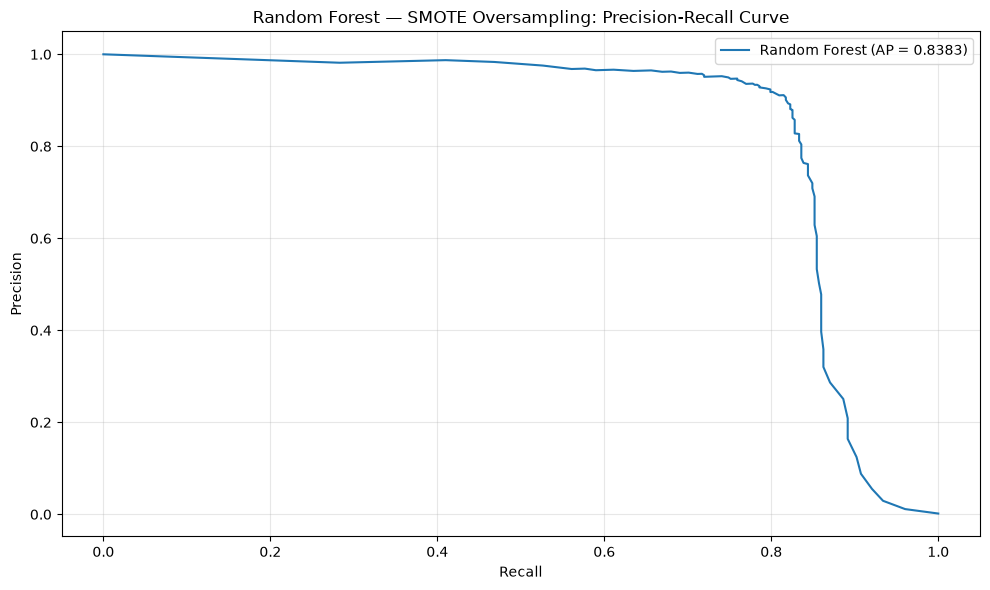

Average Precision: 0.8383


In [43]:
# Calculate precision and recall across thresholds
rf_smote_precision, rf_smote_recall, rf_smote_thresholds = (
    precision_recall_curve(
        y_train,
        rf_smote_oof_probabilities
    )
)

# Calculate Average Precision
rf_smote_ap = average_precision_score(
    y_train,
    rf_smote_oof_probabilities
)

# Plot the curve
plt.figure(figsize=(10, 6))

plt.plot(
    rf_smote_recall,
    rf_smote_precision,
    label=f"Random Forest (AP = {rf_smote_ap:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest — SMOTE Oversampling: Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Average Precision: {rf_smote_ap:.4f}")

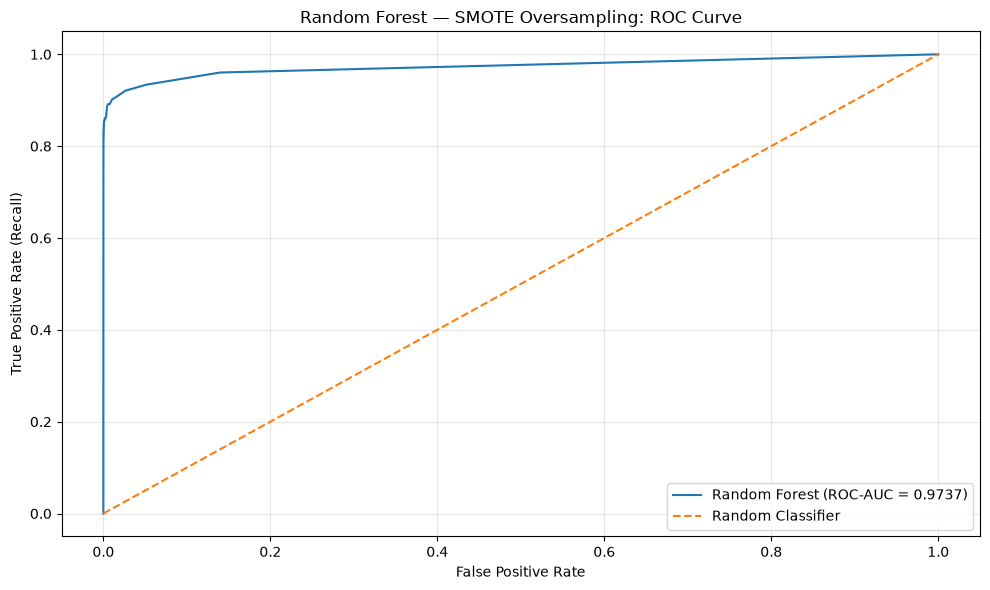

Out-of-fold ROC-AUC: 0.9737


In [44]:
from sklearn.metrics import roc_curve, roc_auc_score

rf_smote_fpr, rf_smote_tpr, rf_smote_roc_thresholds = (
    roc_curve(
        y_train,
        rf_smote_oof_probabilities
    )
)

rf_smote_roc_auc = roc_auc_score(
    y_train,
    rf_smote_oof_probabilities
)

plt.figure(figsize=(10, 6))

plt.plot(
    rf_smote_fpr,
    rf_smote_tpr,
    label=f"Random Forest (ROC-AUC = {rf_smote_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Random Forest — SMOTE Oversampling: ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Out-of-fold ROC-AUC: {rf_smote_roc_auc:.4f}")

In [45]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

thresholds = np.arange(0.1, 1.0, 0.1)

rf_smote_threshold_results = []

for threshold in thresholds:
    predictions = (
        rf_smote_oof_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_train, predictions, zero_division=0
    )

    recall = recall_score(
        y_train, predictions, zero_division=0
    )

    f1 = f1_score(
        y_train, predictions, zero_division=0
    )

    fraud_alerts = predictions.sum()

    rf_smote_threshold_results.append({
        "threshold": round(threshold, 1),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "fraud_alerts": fraud_alerts
    })

rf_smote_threshold_df = pd.DataFrame(
    rf_smote_threshold_results
)

rf_smote_threshold_df.round(4)

,threshold,precision,recall,f1,fraud_alerts
0,0.1,0.3202,0.8624,0.4670,1018
1,0.2,0.6289,0.8519,0.7236,512
2,0.3,0.7841,0.8360,0.8092,403
3,0.4,0.8505,0.8280,0.8391,368
4,0.5,0.8911,0.8228,0.8556,349
5,0.6,0.9179,0.7989,0.8543,329
6,0.7,0.9357,0.7698,0.8447,311
7,0.8,0.9519,0.7328,0.8281,291
8,0.9,0.9620,0.6693,0.7894,263


## 6. Classification Threshold Analysis

The classification threshold determines the minimum predicted fraud probability required for a transaction to be classified as fraudulent.

The default threshold is 0.5. However, this threshold is not necessarily optimal for fraud detection because the costs of missed fraud and false-positive alerts may differ substantially.

To investigate this trade-off, precision, recall, F1 score, and the number of predicted fraud alerts were evaluated at nine classification thresholds.

### Results

| Threshold | Precision | Recall | F1 Score | Fraud Alerts |
|---:|---:|---:|---:|---:|
| 0.1 | 0.3202 | 0.8624 | 0.4670 | 1,018 |
| 0.2 | 0.6289 | 0.8519 | 0.7236 | 512 |
| 0.3 | 0.7841 | 0.8360 | 0.8092 | 403 |
| 0.4 | 0.8505 | 0.8280 | 0.8391 | 368 |
| 0.5 | 0.8911 | 0.8228 | 0.8556 | 349 |
| 0.6 | 0.9179 | 0.7989 | 0.8543 | 329 |
| 0.7 | 0.9357 | 0.7698 | 0.8447 | 311 |
| 0.8 | 0.9519 | 0.7328 | 0.8281 | 291 |
| 0.9 | 0.9620 | 0.6693 | 0.7894 | 263 |

### Observations

**1. Lower thresholds increase recall but generate more alerts.**

At a threshold of 0.1, recall reached 86.24%, the highest among the tested thresholds. However, precision dropped to 32.02%, and the model generated 1,018 fraud alerts.

This indicates that lowering the threshold enables the model to identify more fraudulent transactions but also causes many legitimate transactions to be flagged.

**2. Higher thresholds improve precision but reduce recall.**

At a threshold of 0.9, precision reached 96.20%, while recall declined to 66.93%. The number of alerts decreased to 263.

Although these alerts were highly precise, the model missed a substantially larger proportion of actual fraud cases.

**3. The default threshold provides a useful balance.**

At a threshold of 0.5, precision was 89.11%, recall was 82.28%, and the F1 score was 85.56%.

This threshold achieved the highest F1 score among the nine thresholds evaluated. It therefore provides a useful reference point for balancing precision and recall in this experiment.

**4. Threshold selection depends on operational requirements.**

A fraud detection system designed to minimize missed fraud may accept more false-positive alerts. Conversely, a system with limited investigation capacity may prioritize higher precision, even if that results in more missed fraud.

The appropriate threshold should ultimately reflect the relative costs of false negatives and false positives.

### Conclusion

Random Forest with SMOTE Oversampling demonstrates a clear precision-recall trade-off across classification thresholds.

The default threshold of 0.5 achieved the highest F1 score among the tested values, while lower thresholds increased recall at the expense of precision. Higher thresholds improved precision but reduced fraud detection.

The threshold of 0.5 will remain the reference point for subsequent model comparisons. It is not yet the final production threshold because the other candidate models and the operational costs of different error types have not yet been evaluated.

The final threshold will be selected after candidate comparison and further validation, without using the untouched test set for threshold selection.

In [46]:
catboost_pipeline = build_pipeline(
    model=models["CatBoost"],
    strategy="Class Weighting"
)

catboost_pipeline

,steps,"[('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False


In [47]:
from sklearn.model_selection import cross_val_predict

catboost_oof_probabilities = cross_val_predict(
    catboost_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

print("Out-of-fold predictions generated.")
print(
    "Number of predictions:",
    len(catboost_oof_probabilities)
)

Out-of-fold predictions generated.
Number of predictions: 226980


In [50]:
catboost_oof_predictions = (
    catboost_oof_probabilities >= 0.5
).astype(int)

catboost_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "Average Precision",
        "ROC-AUC"
    ],
    "Value": [
        accuracy_score(y_train, catboost_oof_predictions),
        precision_score(y_train, catboost_oof_predictions, zero_division=0),
        recall_score(y_train, catboost_oof_predictions, zero_division=0),
        f1_score(y_train, catboost_oof_predictions, zero_division=0),
        average_precision_score(y_train, catboost_oof_probabilities),
        roc_auc_score(y_train, catboost_oof_probabilities)
    ]
})

catboost_metrics.round(4)

,Metric,Value
0,Accuracy,0.9994
1,Precision,0.8175
2,Recall,0.8413
3,F1 Score,0.8292
4,Average Precision,0.8378
5,ROC-AUC,0.9757


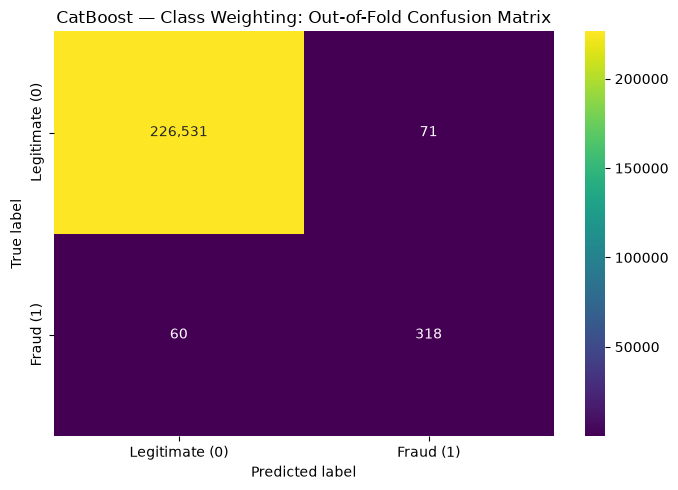

In [51]:

catboost_cm = confusion_matrix(
    y_train,
    catboost_oof_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    catboost_cm,
    annot=True,
    fmt=",",
    cmap="viridis",
    xticklabels=["Legitimate (0)", "Fraud (1)"],
    yticklabels=["Legitimate (0)", "Fraud (1)"]
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("CatBoost — Class Weighting: Out-of-Fold Confusion Matrix")
plt.tight_layout()
plt.show()

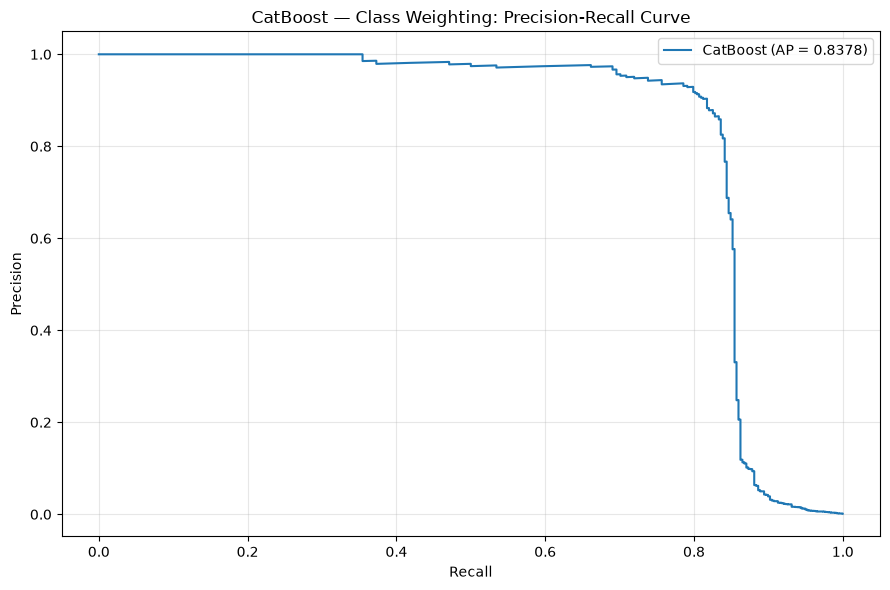

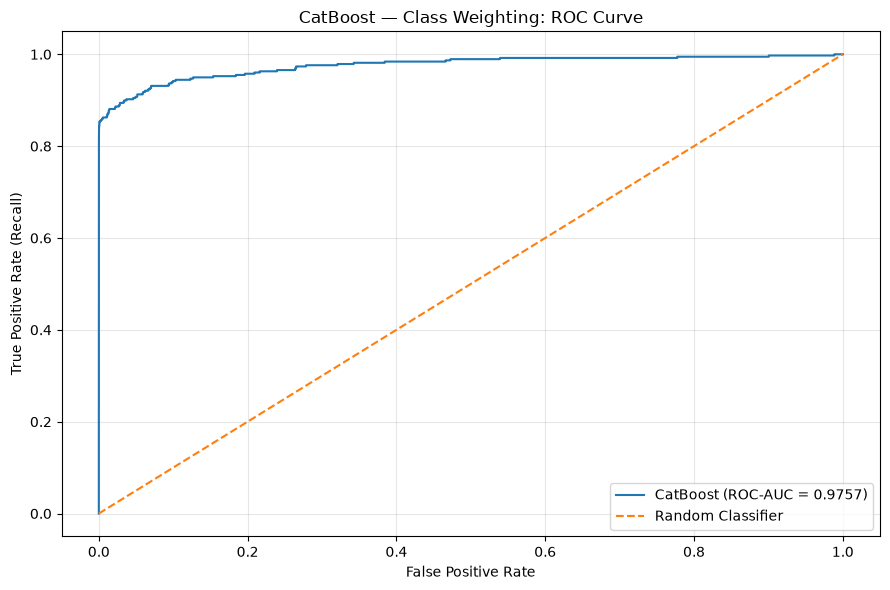

In [52]:
# Precision-Recall Curve
precision, recall, _ = precision_recall_curve(
    y_train,
    catboost_oof_probabilities
)

average_precision = average_precision_score(
    y_train,
    catboost_oof_probabilities
)

plt.figure(figsize=(9, 6))
plt.plot(
    recall,
    precision,
    label=f"CatBoost (AP = {average_precision:.4f})"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("CatBoost — Class Weighting: Precision-Recall Curve")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ROC Curve
fpr, tpr, _ = roc_curve(
    y_train,
    catboost_oof_probabilities
)

roc_auc = roc_auc_score(
    y_train,
    catboost_oof_probabilities
)

plt.figure(figsize=(9, 6))
plt.plot(
    fpr,
    tpr,
    label=f"CatBoost (ROC-AUC = {roc_auc:.4f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("CatBoost — Class Weighting: ROC Curve")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [53]:
thresholds = np.arange(0.1, 1.0, 0.1)

catboost_threshold_results = []

for threshold in thresholds:
    predictions = (
        catboost_oof_probabilities >= threshold
    ).astype(int)

    catboost_threshold_results.append({
        "threshold": round(threshold, 1),
        "precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "fraud_alerts": int(predictions.sum())
    })

catboost_threshold_df = pd.DataFrame(
    catboost_threshold_results
)

catboost_threshold_df.round(4)

,threshold,precision,recall,f1,fraud_alerts
0,0.1,0.4939,0.8545,0.6260,654
1,0.2,0.6414,0.8519,0.7318,502
2,0.3,0.7283,0.8439,0.7819,438
3,0.4,0.7775,0.8413,0.8081,409
4,0.5,0.8175,0.8413,0.8292,389
5,0.6,0.8404,0.8360,0.8382,376
6,0.7,0.8587,0.8360,0.8472,368
7,0.8,0.8785,0.8228,0.8497,354
8,0.9,0.9032,0.8148,0.8567,341



# CatBoost with Class Weighting: Model Evaluation and Investigation

## 1. Overview

This experiment evaluates CatBoost with Class Weighting for the credit card fraud detection task.

The objective is to determine how effectively the model distinguishes fraudulent transactions from legitimate transactions, understand its classification errors, and investigate how changing the classification threshold affects fraud detection.

The evaluation uses out-of-fold (OOF) predictions generated through five-fold stratified cross-validation on the training dataset. Each observation receives a prediction from a model that was not trained on that observation.

The classification threshold of 0.5 is used for the initial evaluation. Additional thresholds are examined to understand the trade-off between precision and recall.

### Experimental configuration

- **Model:** CatBoost Classifier
- **Imbalance-handling strategy:** Class Weighting
- **Validation approach:** Five-fold Stratified Cross-Validation
- **Evaluation predictions:** Out-of-fold predicted probabilities
- **Default classification threshold:** 0.5
- **Positive class:** Fraudulent transactions (Class 1)
- **Negative class:** Legitimate transactions (Class 0)

---

## 2. Evaluation Metrics

The model was evaluated using accuracy, precision, recall, F1 score, Average Precision, and ROC-AUC.

| Metric | Value |
|---|---:|
| Accuracy | 0.9994 |
| Precision | 0.8175 |
| Recall | 0.8413 |
| F1 Score | 0.8292 |
| Average Precision | 0.8378 |
| ROC-AUC | 0.9757 |

### 2.1 Accuracy

Accuracy measures the proportion of all transactions classified correctly.

The model achieved an accuracy of approximately **99.94%**.

Although this is a high value, accuracy must be interpreted carefully because legitimate transactions greatly outnumber fraudulent transactions. A model can achieve high accuracy while failing to detect a substantial proportion of fraud.

Consequently, accuracy is not sufficient for selecting the best fraud detection model.

### 2.2 Precision

Precision measures the proportion of transactions predicted as fraudulent that are genuinely fraudulent.

The model achieved a precision of **81.75%** at the default threshold.

This means that approximately 81.75% of the transactions flagged as fraud were actually fraudulent. The remaining alerts were legitimate transactions incorrectly classified as fraudulent.

Higher precision reduces the proportion of false-positive alerts and can reduce the workload associated with investigating transactions.

### 2.3 Recall

Recall measures the proportion of actual fraudulent transactions that the model successfully identifies.

The model achieved a recall of **84.13%**.

This means that approximately 84.13% of the fraudulent transactions in the out-of-fold evaluation were detected, while approximately 15.87% were missed.

Recall is important in fraud detection because missed fraudulent transactions can result in financial losses.

### 2.4 F1 Score

The F1 score is the harmonic mean of precision and recall.

The model achieved an F1 score of **82.92%** at the default threshold.

This provides a single measure of the balance between detecting fraudulent transactions and limiting false-positive alerts.

However, F1 does not account for the actual financial cost of either type of error. The highest F1 score is therefore not necessarily the best operational choice.

### 2.5 Average Precision

The model achieved an Average Precision score of **0.8378**.

Average Precision summarizes the precision-recall relationship across classification thresholds. It is particularly useful for evaluating models on highly imbalanced classification problems.

A higher Average Precision generally indicates better precision-recall performance across thresholds.

This metric helps compare the models without relying exclusively on the default classification threshold.

### 2.6 ROC-AUC

The model achieved a ROC-AUC score of **0.9757**.

ROC-AUC measures the model's ability to rank fraudulent transactions above legitimate transactions across different classification thresholds.

The result indicates strong discrimination between the two classes.

However, ROC-AUC does not determine the appropriate operating threshold, nor does it directly indicate the number of false-positive alerts the system will generate at a particular threshold.

---

## 3. Confusion Matrix Analysis

The confusion matrix at the default classification threshold of 0.5 produced the following results.

| Actual Class | Predicted Legitimate (0) | Predicted Fraud (1) |
|---|---:|---:|
| Legitimate (0) | 226,531 | 71 |
| Fraud (1) | 60 | 318 |

The matrix contains four possible classification outcomes.

### 3.1 True Negatives: 226,531

These are legitimate transactions correctly classified as legitimate.

The model correctly rejected 226,531 legitimate transactions as potential fraud.

### 3.2 False Positives: 71

These are legitimate transactions incorrectly classified as fraudulent.

They represent false-positive fraud alerts. In an operational system, these transactions may require further investigation even though they are legitimate.

Reducing false positives can lower investigation costs and reduce unnecessary disruption to legitimate customers.

### 3.3 False Negatives: 60

These are fraudulent transactions incorrectly classified as legitimate.

They represent missed fraud cases.

False negatives are important because fraudulent transactions that go undetected may result in financial losses.

### 3.4 True Positives: 318

These are fraudulent transactions correctly classified as fraudulent.

The model successfully identified 318 fraudulent transactions in the out-of-fold predictions.

### 3.5 Operational interpretation

The confusion matrix shows that the model identified 318 fraudulent transactions, missed 60 fraudulent transactions, and generated 71 false-positive alerts.

At this threshold, the model detected approximately 84.13% of the fraud cases represented in the out-of-fold predictions.

The results indicate a useful balance between fraud detection and false-positive control, although the appropriate balance depends on the operational costs associated with each type of error.

---

## 4. Precision-Recall Curve Analysis

The Precision-Recall curve evaluates how precision changes as recall changes across classification thresholds.

The model achieved an Average Precision score of **0.8378**.

### Observations

**High precision at lower recall levels**

Precision remains close to 1.0 across the lower-recall region. This indicates that the model can identify a subset of fraudulent transactions with relatively few false-positive alerts.

**Strong performance at moderate recall levels**

Precision remains high through much of the moderate-recall region, although it begins to decline as the model attempts to detect more fraudulent transactions.

**Sharp decline at higher recall levels**

The curve shows a substantial decline in precision at approximately 0.82–0.85 recall.

This indicates that detecting additional fraudulent transactions becomes increasingly difficult without also flagging more legitimate transactions.

**Performance at very high recall**

As recall approaches 1.0, precision approaches zero. At these extreme operating points, the model flags many transactions as fraudulent to capture nearly all actual fraud cases.

### Interpretation

CatBoost demonstrates strong precision-recall performance, but its effectiveness depends on the chosen classification threshold.

The curve illustrates the practical trade-off between detecting more fraud and controlling the number of false-positive alerts.

A threshold should therefore be selected according to the relative costs of missed fraud and unnecessary investigations rather than assuming that maximum recall is always desirable.

---

## 5. ROC Curve Analysis

The ROC curve plots the true-positive rate against the false-positive rate across classification thresholds.

The model achieved a ROC-AUC score of **0.9757**.

### Observations

**Steep rise near the left side**

The curve rises sharply near the left edge, indicating that the model can identify a substantial proportion of fraudulent transactions at relatively low false-positive rates for suitable thresholds.

**Performance above the random-classifier reference**

The ROC curve remains well above the diagonal reference line. This indicates substantially better discrimination than random ranking.

**Strong overall discrimination**

The ROC-AUC score of 0.9757 indicates that the model can distinguish between fraudulent and legitimate transactions effectively across thresholds.

### Interpretation

CatBoost has strong ranking ability. However, ROC-AUC does not tell us which threshold should be used in a deployed fraud detection system.

Because fraud is rare, the ROC curve should be interpreted alongside the Precision-Recall curve and the confusion matrix.

The Precision-Recall curve provides additional insight into the proportion of fraud alerts that are genuine, while the confusion matrix shows the concrete classification outcomes at a selected threshold.

---

## 6. Classification Threshold Analysis

The default classification threshold is 0.5. However, changing the threshold alters the model's balance between precision and recall.

Nine thresholds, ranging from 0.1 to 0.9, were evaluated using the out-of-fold predicted probabilities.

### Results

| Threshold | Precision | Recall | F1 Score | Fraud Alerts |
|---:|---:|---:|---:|---:|
| 0.1 | 0.4939 | 0.8544 | 0.6260 | 654 |
| 0.2 | 0.6414 | 0.8519 | 0.7318 | 502 |
| 0.3 | 0.7283 | 0.8439 | 0.7819 | 438 |
| 0.4 | 0.7775 | 0.8413 | 0.8081 | 409 |
| 0.5 | 0.8175 | 0.8413 | 0.8292 | 389 |
| 0.6 | 0.8404 | 0.8360 | 0.8382 | 376 |
| 0.7 | 0.8587 | 0.8360 | 0.8472 | 368 |
| 0.8 | 0.8785 | 0.8228 | 0.8497 | 354 |
| 0.9 | 0.9032 | 0.8148 | 0.8567 | 341 |

### 6.1 Effect of lower thresholds

At a threshold of 0.1, recall reaches 85.44%, the highest among the tested thresholds.

However, precision falls to 49.39%, and the model generates 654 fraud alerts.

This demonstrates that lowering the threshold allows the model to identify more fraudulent transactions but also increases false-positive alerts.

### 6.2 Effect of higher thresholds

As the threshold increases, precision improves and the number of alerts decreases.

At a threshold of 0.9, precision reaches 90.32%, while recall remains at 81.48%. The model generates 341 alerts.

Compared with the threshold of 0.5, the threshold of 0.9 produces fewer alerts and higher precision, with a relatively small decrease in recall.

### 6.3 F1 score comparison

The highest F1 score among the nine tested thresholds is **0.8567 at a threshold of 0.9**.

The F1 score at the default threshold of 0.5 is 0.8292.

This suggests that the default threshold may not provide the best precision-recall balance for this model.

However, the threshold of 0.9 should be treated as a candidate for further validation rather than a finalized production decision.

### 6.4 Fraud alerts

The fraud-alert count represents the total number of transactions predicted as fraudulent, including both true positives and false positives.

As the threshold increases from 0.1 to 0.9, the number of alerts decreases from 654 to 341.

This reduction could lower investigation workload, but the associated reduction in recall must also be considered.

### 6.5 Threshold selection considerations

The appropriate threshold depends on the operational objective.

- If missed fraud is extremely costly, a lower threshold may be justified to prioritize recall.
- If investigation capacity is limited, a higher threshold may be preferable to reduce false-positive alerts.
- If precision and recall are to be balanced equally through F1, the threshold of 0.9 is the strongest candidate among those tested.

The final threshold should be selected using validation results and the costs of false positives and false negatives. The untouched test set must not be used to repeatedly choose or optimize the threshold.

---

## 7. Overall Findings

The CatBoost Classifier with Class Weighting demonstrates strong ability to distinguish fraudulent transactions from legitimate transactions.

The main findings are:

1. **Strong discrimination:** ROC-AUC of 0.9757 indicates good ranking performance.
2. **Good precision-recall performance:** Average Precision of 0.8378 indicates strong performance across classification thresholds.
3. **Useful default-threshold performance:** At threshold 0.5, precision is 81.75% and recall is 84.13%.
4. **False-positive control:** The default-threshold confusion matrix contains 71 false positives and 60 false negatives.
5. **Threshold sensitivity:** Increasing the threshold improves precision and reduces alerts, while recall declines.
6. **Best tested F1 score:** A threshold of 0.9 achieves an F1 score of 0.8567 among the nine tested thresholds.

### Limitations

These results are based on out-of-fold predictions from the training dataset. They are not final test-set results.

The selected threshold has not been validated on the untouched test set, and the operational costs of false positives and false negatives have not yet been quantified.

The results should therefore be interpreted as evidence for comparing candidate models rather than proof of production readiness.

---

## 8. Conclusion

CatBoost with Class Weighting is a strong candidate for credit card fraud detection.

At the default threshold of 0.5, it detects approximately 84.13% of fraudulent transactions, with precision of 81.75%. The confusion matrix shows 318 detected fraud cases, 60 missed fraud cases, and 71 false-positive alerts.

Threshold analysis shows that increasing the threshold to 0.9 improves precision to 90.32% and produces the highest F1 score among the nine thresholds evaluated, while recall remains at 81.48%.

This makes 0.9 a candidate threshold for further validation, not a final production decision.

The next step is to compare CatBoost with XGBoost and Random Forest using consistent evaluation criteria. The final model and operating threshold should be selected based on validation performance, the relative costs of classification errors, and final evaluation on the untouched test set.